In [1]:
print("Hello Pravin!")
print("Oasis Infobyte - Data Analytics Task 1")

Hello Pravin!
Oasis Infobyte - Data Analytics Task 1


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail-sales-dataset.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
df.head()


Dataset loaded successfully!
Dataset Shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


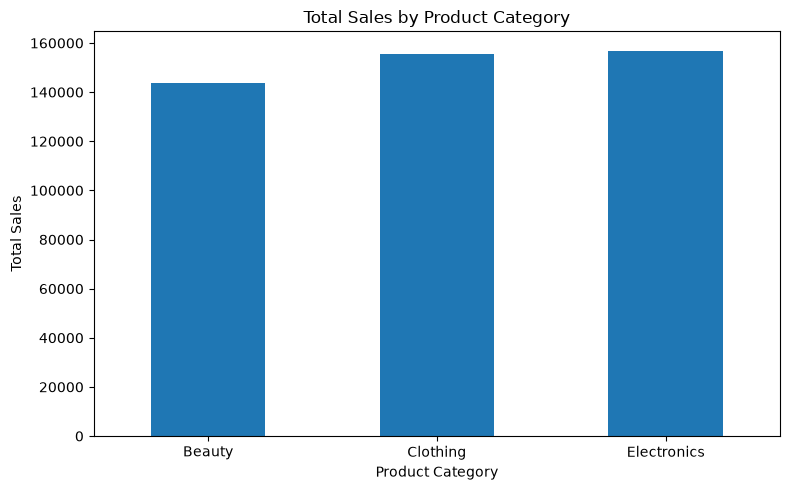

In [4]:

# Sales by Product Category

category_sales = df.groupby("Product Category")["Total Amount"].sum()

plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


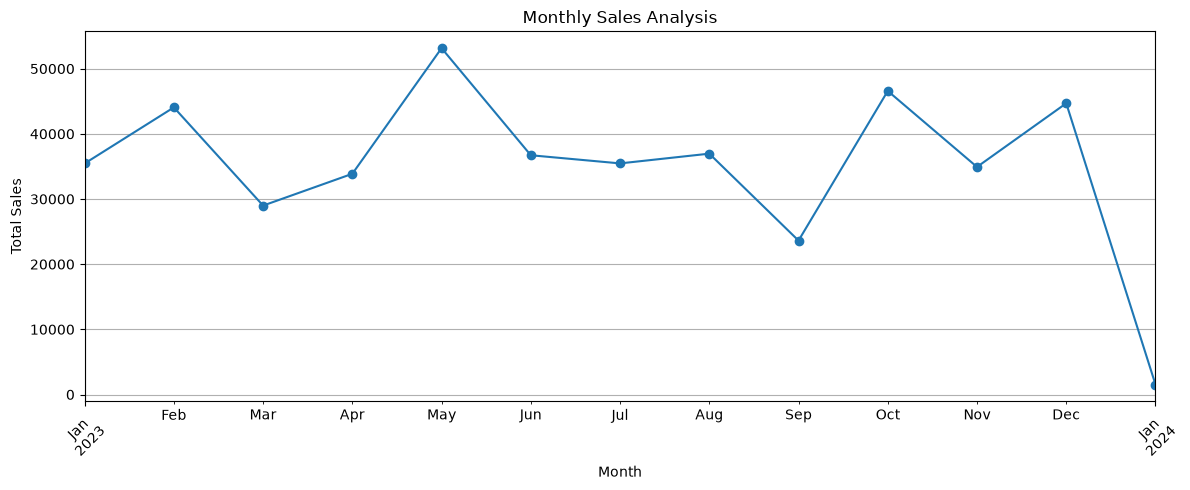

In [5]:

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Calculate monthly sales
monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Total Amount"]
    .sum()
)

# Create chart
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Transactions by Gender:
Gender
Female    510
Male      490
Name: count, dtype: int64


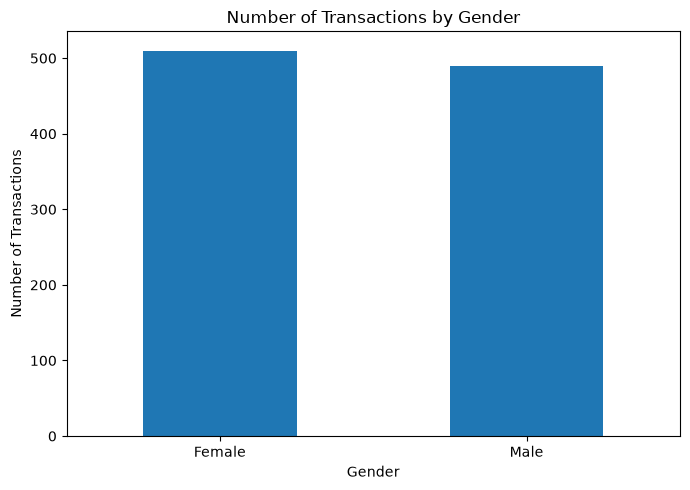

In [6]:

# Gender Analysis
gender_counts = df["Gender"].value_counts()

print("Transactions by Gender:")
print(gender_counts)

# Create chart
plt.figure(figsize=(7, 5))
gender_counts.plot(kind="bar")

plt.title("Number of Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Transactions by Age Group:
Age Group
Under 20     42
20-29       209
30-39       191
40-49       222
50-59       221
60+         115
Name: count, dtype: int64


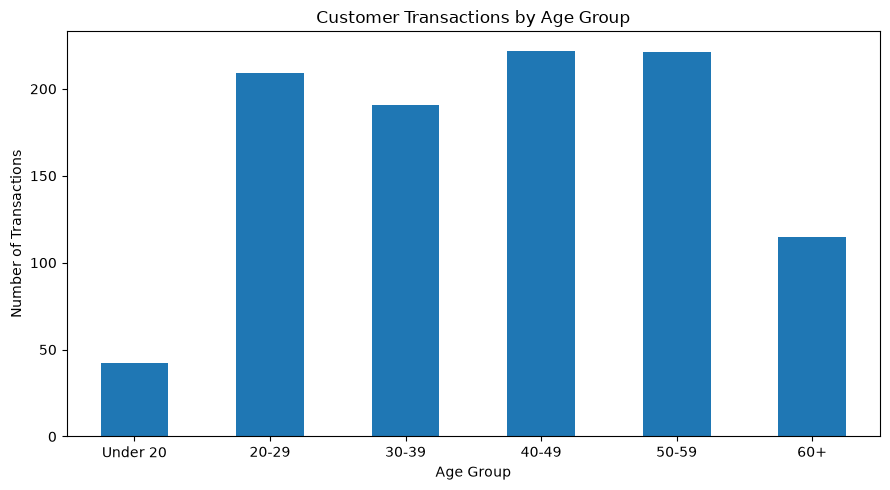

In [7]:

# Age Group Analysis

df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 19, 29, 39, 49, 59, 100],
    labels=["Under 20", "20-29", "30-39", "40-49", "50-59", "60+"]
)

age_counts = df["Age Group"].value_counts().sort_index()

print("Transactions by Age Group:")
print(age_counts)

plt.figure(figsize=(9, 5))
age_counts.plot(kind="bar")

plt.title("Customer Transactions by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


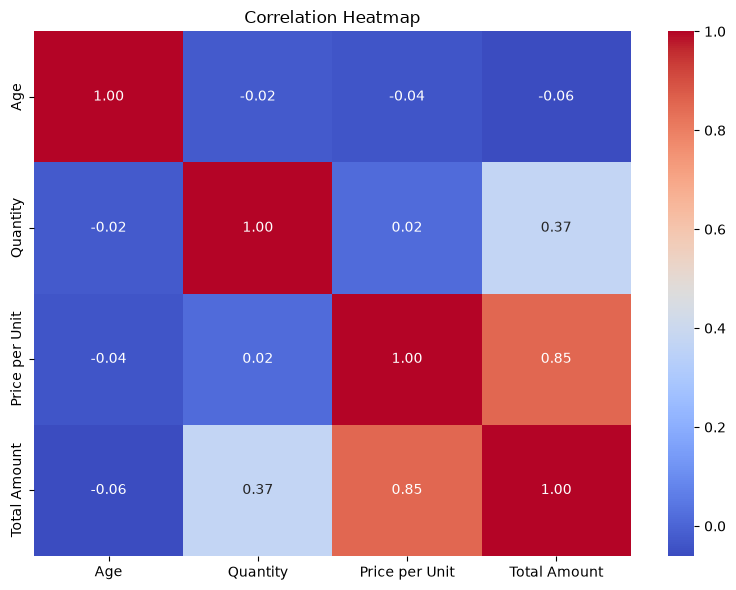

In [8]:

# Correlation Heatmap

numeric_df = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
]

correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()



# Key Findings

1. The dataset contains 1,000 retail transactions.
2. The dataset contains 9 columns.
3. No missing values were found in the dataset.
4. The average customer age is approximately 41 years.
5. The average transaction amount is 456.
6. Electronics, Clothing, and Beauty are the main product categories.
7. Customer transactions can be compared by gender and age group.
8. Monthly sales analysis helps identify changes in sales over time.

# Conclusion

Exploratory Data Analysis (EDA) helped us understand the retail sales dataset using Python. Pandas was used for data analysis, while Matplotlib and Seaborn were used to create visualizations. The analysis provides insights into sales, customer demographics, and product categories.
